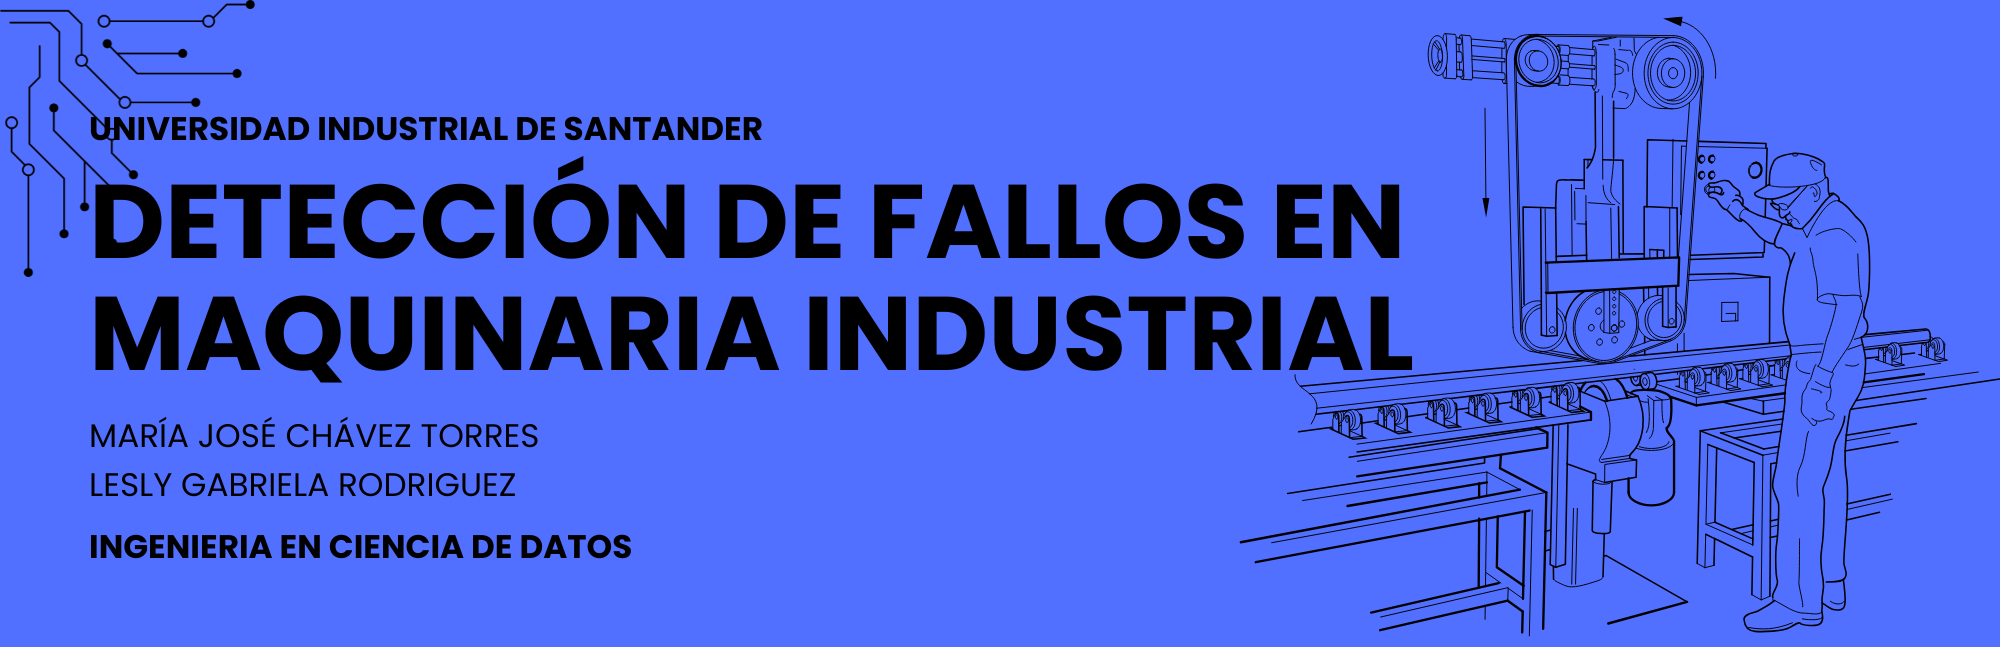



# **Proyecto de Machine Learning: Detección de Fallos en Mantenimiento Predictivo**

In [ ]:
#@title librerias importadas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import *

In [ ]:
# cargar el dataset
url = 'https://raw.githubusercontent.com/gabbrod/Deteccion-de-Fallas-en-manteniminero-Predictivo/refs/heads/main/data/predictive_maintenance.csv'
df = pd.read_csv(url)

In [ ]:
df['Temp_diff'] = df['Process temperature [K]'] - df['Air temperature [K]']
variables_numericas = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

In [ ]:
#String a categorico variable 'Type'
dummies = pd.get_dummies(df["Type"], prefix="Type", dtype=int)
df = pd.concat([df, dummies], axis=1)

df[["Type", "Type_H", "Type_L", "Type_M"]].head(10)

,Type,Type_H,Type_L,Type_M
0,M,0,0,1
1,L,0,1,0
2,L,0,1,0
3,L,0,1,0
4,L,0,1,0
5,M,0,0,1
6,L,0,1,0
7,L,0,1,0
8,M,0,0,1
9,M,0,0,1


In [ ]:

df_completo = df.copy()

df = df[df["Failure Type"] != "Random Failures"].reset_index(drop=True)

print(df.shape)

(9982, 14)


In [ ]:
pd.crosstab(df_completo["Target"], df_completo["Failure Type"])

Failure Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure
Target,,,,,,
0,0,9643,0,0,18,0
1,112,9,78,95,0,45


Se elimina la clase `Random Failures` porque presenta una inconsistencia: aparece como un tipo de falla en `Failure Type`, pero en `Target` sale como que la máquina no falló. Más adelante se comparará el modelo con y sin esta clase usando la métrica principal, para sustentar la elimiación de esta variable

In [ ]:
#String a categorico variable'Failure_Type'

df["Failure Type"] = df["Failure Type"].astype("category")
print(df["Failure Type"].dtype)
y_multi = df["Failure Type"].cat.codes
nombres_clases = list(df["Failure Type"].cat.categories)
print(dict(enumerate(nombres_clases)))
y_bin = df["Target"]

category
{0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Tool Wear Failure'}


# **Fase 1: De n clases a dos clases**

Para elegir el mejor modelo se reduce el problema multiclase (`Failure Type`, 6 clases) a un problema binario: ¿falló o no falló? En este proyecto esa reducción ya existe en la columna `Target`.

$$y_i^{\mathrm{bin}}=\begin{cases}0 & \text{si } y_i=\text{No Failure}\\ 1 & \text{en otro caso}\end{cases}$$

In [ ]:
#@title **Verificación de la variable binaria y cruce con el tipo de falla**
print(y_bin.value_counts())
print(y_bin.value_counts(normalize=True).round(4))
pd.crosstab(df["Target"], df["Failure Type"])

Target
0    9643
1     339
Name: count, dtype: int64
Target
0    0.966
1    0.034
Name: proportion, dtype: float64


Failure Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Tool Wear Failure
Target,,,,,
0,0,9643,0,0,0
1,112,9,78,95,45


# **Fase 2: definición de la metrica principal**
Para evaluar los modelos se usan métricas calculadas a partir de la matriz de confusión. Cada métrica mide un aspecto distinto: la accuracy el acierto global, la precision qué tan confiables son las alarmas, el recall cuántas fallas se detectan, la especificidad cuántas máquinas sanas se reconocen, y el F1 el equilibrio entre precision y recall.

**Accuracy**

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$


**Recall (sensibilidad)**

$$\text{Recall} = \frac{TP}{TP + FN}$$

**Especificidad**

$$\text{Especificidad} = \frac{TN}{TN + FP}$$

**Precision**

$$\text{Precision} = \frac{TP}{TP + FP}$$

**F1-score**

$$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2\,TP}{2\,TP + FP + FN}$$


Debido al desbalance que presenta la clase `Target`, con 96,61 % de máquinas sin falla, un modelo que siempre responde “no falla” obtiene 0,9661 de accuracy pero no detecta ninguna falla.


In [ ]:
n_total = len(y_bin)
n_fallas = y_bin.sum()
n_sin_falla = n_total - n_fallas

acc_ejem = n_sin_falla / n_total
recall_ejem = 0 / n_fallas

print(f"accuracy = {acc_ejem:.4f} \nRecall = {recall_ejem:.4f}")

accuracy = 0.9660 
Recall = 0.0000


Cuando una clase domina, acertar en esa clase basta para sacar un valor altísimo, el accuracy mezcla los dos tipos de error y le da el mismo peso a todos los aciertos, pero aquí el 96 % de los aciertos faciles tapan lo que importa, que es el 3,39 % de fallas.

### **Definiciones estadísticas**.
De acuerdo con el análisis realizado acerca de como se comporta la distintas metricas, para nuestro entrenamiento escogimos las siguientes:

$$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2\,TP}{2\,TP + FP + FN}$$


$$\text{Recall} = \frac{TP}{TP + FN}$$

$$F_{1,\text{macro}} = \frac{1}{K}\sum_{k=1}^{K} F_{1,k}$$

La métrica principal es el **F1 de la clase de falla**. Con solo 3,39 % de fallas, hay dos maneras de equivocarse: no detectar una falla real (FN) o avisar de una falla que no existe (FP). El recall solo mide el primer error y la precision solo mide el segundo, y es fácil subir uno a costa del otro. El F1 es la media armónica de ambos, así que solo es alto cuando precision y recall lo son, y por eso sirve para elegir el modelo.

El **recall** se usa como métrica de apoyo, porque en mantenimiento predictivo una falla no detectada cuesta más que una revisión innecesaria. Sirve para verificar que el modelo ganador no consiga un F1 alto a costa de dejar pasar muchas fallas.

Para el problema multiclase se usa el **F1 macro**, que promedia el F1 de cada tipo de falla con el mismo peso, de modo que las clases pequeñas cuentan igual que `No Failure`.

## **Fase 3: Partición, Preprocesamiento, Balanceo**

In [ ]:
#Particion de dataset
SEED = 42

X = df.drop(columns=["UDI", "Product ID", "Type", "Target", "Failure Type"])
X_dev, X_test, y_dev_bin, y_test_bin = train_test_split(X, y_bin, test_size=0.20, stratify=y_bin, random_state=SEED)
X_train, X_val, y_train_bin, y_val_bin = train_test_split( X_dev, y_dev_bin, test_size=0.25, stratify=y_dev_bin, random_state=SEED)


y_train_multi = y_multi.loc[X_train.index]
y_val_multi = y_multi.loc[X_val.index]
y_test_multi = y_multi.loc[X_test.index]

### **Balanceo con SMOTE:**
Para el balanceo de las clase se usa la tecnica de SMOTE para que los modelos puedan aprender mejor la clase minoritaria, se generan fallas sinteticas ubicadas entre fallas reales cercanas y se aplica únicamente sobre el conjunto de entrenamiento. Todos los modelo se entrenan con los mismos datos balanceados.

In [ ]:
#Balanceo con SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=SEED)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train_bin)

print("Train original:\n", y_train_bin.value_counts())
print("Train balanceado:\n", y_train_bal.value_counts())

Train original:
 Target
0    5785
1     203
Name: count, dtype: int64
Train balanceado:
 Target
0    5785
1    5785
Name: count, dtype: int64


### **Escalado para SVM:**


El SVM calcula distancias entre las observaciones, por lo que es sensible a la escala de las variables, sin escalar las de mayor magnitud  dominarían sobre las demás. Se usa `RobustScaler`, que escala con la mediana y el rango intercuartílico y es poco sensible a los valores atípicos encontrados. El escalador se ajusta solo con los datos de entrenamiento balanceados y luego se aplica a validación y prueba. Gaussian Naive Bayes, Decision Tree y Random Forest no necesitan escalado, por lo que usan los datos originales.


In [ ]:
scaler = RobustScaler()
scaler.fit(X_train)

X_train_svm = scaler.transform(X_train_bal)
X_val_svm = scaler.transform(X_val)
X_test_svm = scaler.transform(X_test)
print(X_train_svm.shape, X_val_svm.shape, X_test_svm.shape)

(11570, 9) (1997, 9) (1997, 9)


#**Fase 4: entrenar los cuatro modelos base con binario**

En esta fase se entrenan los cuatro modelos vistos en clase para el problema binario (¿ocurrio un falló?), usando la configuración por defecto de sklearn. Cada modelo se entrena con el conjunto de entrenamiento y se evalúa en el conjunto de validación.

| Modelo | Idea (analogía) | Clase de sklearn |
|---|---|---|
| Gaussian Naive Bayes | Un agente que suma caminos independientes, cada una con forma de campana de gauss | `GaussianNB` |
| Decision Tree | Un arbol de elección con preguntas sí/no sujetas | `DecisionTreeClassifier` |
| Random Forest | Un bosque de muchos árboles que votan | `RandomForestClassifier` |
| SVM | Trazar la frontera con el mayor margen posible entre clases | `SVC` (con escalador) |


Para tratar el desbalance de clases (3,39 % de fallas) se aplica SMOTE a todos los modelos, solo sobre los datos de entrenamiento y dentro de un Pipeline, de modo que nunca se modifica la validación ni el test.

In [ ]:
#Definición de las metricas

def metricas(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return {'Accuracy': round(accuracy_score(y_real, y_pred), 4),
            'Precision': round(precision_score(y_real, y_pred, zero_division=0), 4),
            'Recall': round(recall_score(y_real, y_pred, zero_division=0), 4),
            'Especificidad': round(tn / (tn + fp), 4),
            'F1': round(f1_score(y_real, y_pred, zero_division=0), 4)}

base_train = {}
base_val = {}

In [ ]:
# @title **Gaussian Naive Bayes base**

gnb = GaussianNB()
gnb.fit(X_train_bal, y_train_bal)
y_pred_train = gnb.predict(X_train)
y_pred_val = gnb.predict(X_val)

met_train = metricas(y_train_bin, y_pred_train)
met_val = metricas(y_val_bin, y_pred_val)

base_train['Gaussian NB'] = met_train
base_val['Gaussian NB'] = met_val

print(base_val)
print(base_train)

{'Gaussian NB': {'Accuracy': 0.6184, 'Precision': 0.0563, 'Recall': 0.6471, 'Especificidad': np.float64(0.6174), 'F1': 0.1035}}
{'Gaussian NB': {'Accuracy': 0.6306, 'Precision': 0.0642, 'Recall': 0.7291, 'Especificidad': np.float64(0.6271), 'F1': 0.118}}


In [ ]:
# @title **Decision Tree base**

dt = DecisionTreeClassifier(random_state=SEED)
dt.fit(X_train_bal, y_train_bal)
y_pred_train = dt.predict(X_train)
y_pred_val = dt.predict(X_val)

met_train = metricas(y_train_bin, y_pred_train)
met_val = metricas(y_val_bin, y_pred_val)

base_train['Decision Tree'] = met_train
base_val['Decision Tree'] = met_val

print(base_val)
print(base_train)

{'Gaussian NB': {'Accuracy': 0.6184, 'Precision': 0.0563, 'Recall': 0.6471, 'Especificidad': np.float64(0.6174), 'F1': 0.1035}, 'Decision Tree': {'Accuracy': 0.9569, 'Precision': 0.4167, 'Recall': 0.6618, 'Especificidad': np.float64(0.9673), 'F1': 0.5114}}
{'Gaussian NB': {'Accuracy': 0.6306, 'Precision': 0.0642, 'Recall': 0.7291, 'Especificidad': np.float64(0.6271), 'F1': 0.118}, 'Decision Tree': {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'Especificidad': np.float64(1.0), 'F1': 1.0}}


In [ ]:
# @title **Random Forest base**

rf = RandomForestClassifier(random_state=SEED)
rf.fit(X_train_bal, y_train_bal)
y_pred_train = rf.predict(X_train)
y_pred_val = rf.predict(X_val)

met_train = metricas(y_train_bin, y_pred_train)
met_val = metricas(y_val_bin, y_pred_val)

base_train['Random Forest'] = met_train
base_val['Random Forest'] = met_val

print(base_val)
print(base_train)

{'Gaussian NB': {'Accuracy': 0.6184, 'Precision': 0.0563, 'Recall': 0.6471, 'Especificidad': np.float64(0.6174), 'F1': 0.1035}, 'Decision Tree': {'Accuracy': 0.9569, 'Precision': 0.4167, 'Recall': 0.6618, 'Especificidad': np.float64(0.9673), 'F1': 0.5114}, 'Random Forest': {'Accuracy': 0.967, 'Precision': 0.5111, 'Recall': 0.6765, 'Especificidad': np.float64(0.9772), 'F1': 0.5823}}
{'Gaussian NB': {'Accuracy': 0.6306, 'Precision': 0.0642, 'Recall': 0.7291, 'Especificidad': np.float64(0.6271), 'F1': 0.118}, 'Decision Tree': {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'Especificidad': np.float64(1.0), 'F1': 1.0}, 'Random Forest': {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'Especificidad': np.float64(1.0), 'F1': 1.0}}


In [ ]:
# @title **Support Vector Machine base**

svm = SVC(random_state=SEED)
svm.fit(X_train_svm, y_train_bal)

X_train_real_svm = scaler.transform(X_train)
y_pred_train = svm.predict(X_train_real_svm)
y_pred_val = svm.predict(X_val_svm)

met_train = metricas(y_train_bin, y_pred_train)
met_val = metricas(y_val_bin, y_pred_val)

base_train['SVM'] = met_train
base_val['SVM'] = met_val

print(base_val)
print(base_train)

{'Gaussian NB': {'Accuracy': 0.6184, 'Precision': 0.0563, 'Recall': 0.6471, 'Especificidad': np.float64(0.6174), 'F1': 0.1035}, 'Decision Tree': {'Accuracy': 0.9569, 'Precision': 0.4167, 'Recall': 0.6618, 'Especificidad': np.float64(0.9673), 'F1': 0.5114}, 'Random Forest': {'Accuracy': 0.967, 'Precision': 0.5111, 'Recall': 0.6765, 'Especificidad': np.float64(0.9772), 'F1': 0.5823}, 'SVM': {'Accuracy': 0.9409, 'Precision': 0.3333, 'Recall': 0.7353, 'Especificidad': np.float64(0.9482), 'F1': 0.4587}}
{'Gaussian NB': {'Accuracy': 0.6306, 'Precision': 0.0642, 'Recall': 0.7291, 'Especificidad': np.float64(0.6271), 'F1': 0.118}, 'Decision Tree': {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'Especificidad': np.float64(1.0), 'F1': 1.0}, 'Random Forest': {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'Especificidad': np.float64(1.0), 'F1': 1.0}, 'SVM': {'Accuracy': 0.9466, 'Precision': 0.3774, 'Recall': 0.8867, 'Especificidad': np.float64(0.9487), 'F1': 0.5294}}


In [ ]:
tabla_base_train = pd.DataFrame(base_train).T.round(4)
tabla_base_val = pd.DataFrame(base_val).T.round(4)

print("Métricas en entrenamiento")
display(tabla_base_train)

print("\nMétricas en validación")
display(tabla_base_val)

# diferencia de F1 entre train y validación
brecha = (tabla_base_train['F1'] - tabla_base_val['F1']).round(4)
print("\nDiferencia de F1 (train - validación)")
display(brecha.to_frame('Brecha F1'))

Métricas en entrenamiento


,Accuracy,Precision,Recall,Especificidad,F1
Gaussian NB,0.6306,0.0642,0.7291,0.6271,0.1180
Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
SVM,0.9466,0.3774,0.8867,0.9487,0.5294



Métricas en validación


,Accuracy,Precision,Recall,Especificidad,F1
Gaussian NB,0.6184,0.0563,0.6471,0.6174,0.1035
Decision Tree,0.9569,0.4167,0.6618,0.9673,0.5114
Random Forest,0.9670,0.5111,0.6765,0.9772,0.5823
SVM,0.9409,0.3333,0.7353,0.9482,0.4587



Diferencia de F1 (train - validación)


,Brecha F1
Gaussian NB,0.0145
Decision Tree,0.4886
Random Forest,0.4177
SVM,0.0707


## **Fase 5: Variación de los hiperparámetros**
Para cada modelo se varía su hiperparámetro principal y se entrena con el conjunto de entrenamiento balanceado,
Se mide el `F1-Score` de la clase de falla en entrenamiento y en validación.
| Modelo | Hiperparámetro | Valores a probar |
|---|---|---|
| Gaussian Naive Bayes | `var_smoothing` | $10^{-9}$, $10^{-7}$, $10^{-5}$, $10^{-3}$, $10^{-1}$ |
| Decision Tree | `max_depth` | 1, 2, 4, 8, `None` |
| Random Forest | `n_estimators` | 10, 50, 100, 200 |
| SVM (kernel `rbf`) | `C` | 0.1, 1, 10 |
| SVM (kernel `rbf`) | `gamma` | 0.01, 0.1, 1 |

Métricas en train


,Accuracy,Precision,Recall,Especificidad,F1
var_smoothing,,,,,
1.000000e-09,0.630595,0.064208,0.729064,0.627139,0.118022
1.000000e-07,0.671009,0.072155,0.733990,0.668799,0.131393
1.000000e-05,0.820140,0.141803,0.852217,0.819015,0.243148
1.000000e-03,0.883100,0.182631,0.704433,0.889369,0.290061
1.000000e-01,0.902639,0.120000,0.295567,0.923941,0.170697




Métricas en validacion


,Accuracy,Precision,Recall,Especificidad,F1
var_smoothing,,,,,
1.000000e-09,0.618428,0.056266,0.647059,0.617418,0.103529
1.000000e-07,0.659990,0.062947,0.647059,0.660446,0.114733
1.000000e-05,0.826239,0.146835,0.852941,0.825298,0.250540
1.000000e-03,0.878317,0.177122,0.705882,0.884396,0.283186
1.000000e-01,0.908363,0.138365,0.323529,0.928979,0.193833


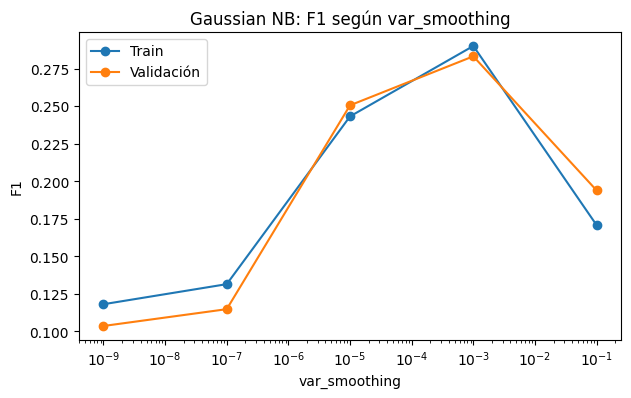

In [ ]:
# @title **Gaussian Naive Bayes**
def metricas(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return {'Accuracy': accuracy_score(y_real, y_pred),
            'Precision': precision_score(y_real, y_pred, zero_division=0),
            'Recall': recall_score(y_real, y_pred, zero_division=0),
            'Especificidad': tn / (tn + fp),
            'F1': f1_score(y_real, y_pred, zero_division=0)}

valores = [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]
filas_train, filas_val = [], []

for vs in valores:
    gnb = GaussianNB(var_smoothing=vs)
    gnb.fit(X_train_bal, y_train_bal)
    filas_train.append({'var_smoothing': vs, **metricas(y_train_bin, gnb.predict(X_train))})
    filas_val.append({'var_smoothing': vs, **metricas(y_val_bin, gnb.predict(X_val))})

tabla_train = pd.DataFrame(filas_train).set_index('var_smoothing')
tabla_val = pd.DataFrame(filas_val).set_index('var_smoothing')

print("Métricas en train")
display(tabla_train)
print("\n\nMétricas en validacion")
display(tabla_val)

plt.figure(figsize=(7, 4))
plt.plot(valores, tabla_train['F1'], marker='o', label='Train')
plt.plot(valores, tabla_val['F1'], marker='o', label='Validación')
plt.xscale('log')
plt.xlabel('var_smoothing')
plt.ylabel('F1')
plt.title('Gaussian NB: F1 según var_smoothing')
plt.legend()
plt.show()

**Resultados Gaussian Naive Bayes.**

Con valores bajos de `var_smoothing`el F1 es cercano a 0,1, con muchos falsos positivos.
El F1 de validación mejora hasta 0,283 con `var_smoothing = 1e-3` y vuelve a bajar con `1e-1`, donde el recall cae a 0,32.

Los F1 de entrenamiento y validación son casi iguales en todos los valores, por lo que no hay sobreajuste.

Se elige `var_smoothing = 1e-3`, que tiene el mayor F1 de validación.


Métricas en Train


,Accuracy,Precision,Recall,Especificidad,F1
max_depth,,,,,
1,0.866065,0.153757,0.655172,0.873466,0.249064
2,0.818136,0.138662,0.837438,0.817459,0.237929
4,0.930528,0.317949,0.916256,0.931029,0.472081
8,0.969773,0.529730,0.965517,0.969922,0.684119
None,1.000000,1.000000,1.000000,1.000000,1.000000




Métricas en Validacion


,Accuracy,Precision,Recall,Especificidad,F1
max_depth,,,,,
1,0.869805,0.141791,0.558824,0.880767,0.226190
2,0.823736,0.137755,0.794118,0.824780,0.234783
4,0.929895,0.314433,0.897059,0.931052,0.465649
8,0.947421,0.368794,0.764706,0.953862,0.497608
None,0.956935,0.416667,0.661765,0.967341,0.511364


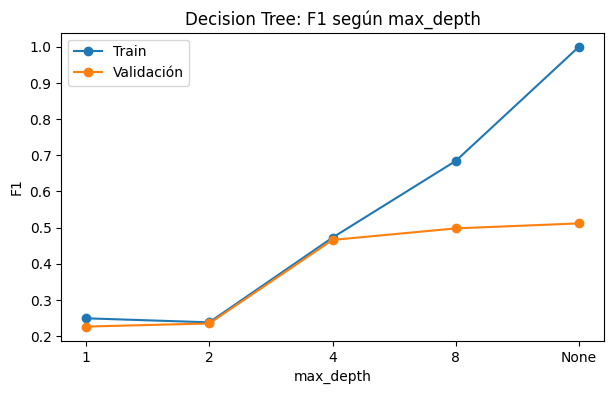

In [ ]:
# @title **Decision Tree**
valores = [1, 2, 4, 8, None]
filas_train, filas_val = [], []

for d in valores:
    dt = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    dt.fit(X_train_bal, y_train_bal)
    filas_train.append({'max_depth': str(d), **metricas(y_train_bin, dt.predict(X_train))})
    filas_val.append({'max_depth': str(d), **metricas(y_val_bin, dt.predict(X_val))})

tabla_train = pd.DataFrame(filas_train).set_index('max_depth')
tabla_val = pd.DataFrame(filas_val).set_index('max_depth')

print("Métricas en Train")
display(tabla_train)
print("\n\nMétricas en Validacion")
display(tabla_val)

plt.figure(figsize=(7, 4))
plt.plot(tabla_train.index, tabla_train['F1'], marker='o', label='Train')
plt.plot(tabla_val.index, tabla_val['F1'], marker='o', label='Validación')
plt.xlabel('max_depth')
plt.ylabel('F1')
plt.title('Decision Tree: F1 según max_depth')
plt.legend()
plt.show()

**Resultados Decision Tree.**

Con `max_depth` de 1 y 2 el árbol presenta subajuste, y el F1 de validación sube hasta 0,498 con `max_depth = 8`.

Sin límite de profundidad el F1 de validación es 0,511, pero el F1 de entrenamiento es 1,000. Una diferencia tan grande entre entrenamiento y validación indica un sobreajuste, el árbol memorizó los datos de entrenamiento y no generaliza a datos nuevos.

Con `max_depth = 8` la diferencia baja a 0,19 y el recall en validación es mayor.

Se elige `max_depth = 8`, que tiene un F1 de validación casi igual al máximo, pero con menos sobreajuste.

Métricas en entrenamiento


,Accuracy,Precision,Recall,Especificidad,F1
n_estimators,,,,,
10,0.998664,0.97561,0.985222,0.999136,0.980392
50,1.000000,1.00000,1.000000,1.000000,1.000000
100,1.000000,1.00000,1.000000,1.000000,1.000000
200,1.000000,1.00000,1.000000,1.000000,1.000000


Métricas en validación


,Accuracy,Precision,Recall,Especificidad,F1
n_estimators,,,,,
10,0.970456,0.551724,0.705882,0.979782,0.619355
50,0.967952,0.521739,0.705882,0.977190,0.600000
100,0.966950,0.511111,0.676471,0.977190,0.582278
200,0.968953,0.534091,0.691176,0.978745,0.602564


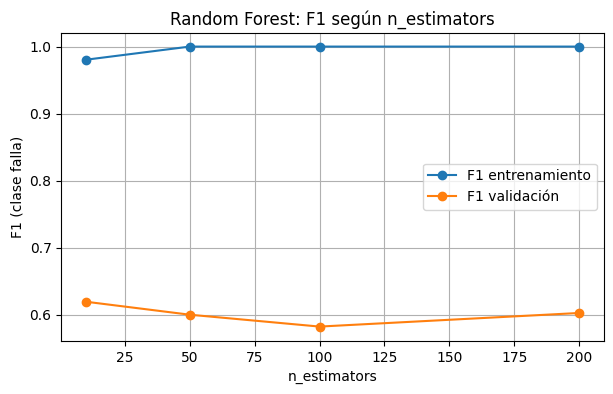

In [ ]:
#@title **Random Forest**

valores_rf = [10, 50, 100, 200]

filas_train = []
filas_val = []

for n in valores_rf:
    rf = RandomForestClassifier(n_estimators=n, random_state=SEED)
    rf.fit(X_train_bal, y_train_bal)

    pred_train = rf.predict(X_train)
    pred_val = rf.predict(X_val)

    fila_train = metricas(y_train_bin, pred_train)
    fila_train['n_estimators'] = n
    filas_train.append(fila_train)

    fila_val = metricas(y_val_bin, pred_val)
    fila_val['n_estimators'] = n
    filas_val.append(fila_val)

tabla_rf_train = pd.DataFrame(filas_train).set_index('n_estimators')
tabla_rf_val = pd.DataFrame(filas_val).set_index('n_estimators')

print("Métricas en entrenamiento")
display(tabla_rf_train)

print("Métricas en validación")
display(tabla_rf_val)

plt.figure(figsize=(7, 4))
plt.plot(valores_rf, tabla_rf_train['F1'], marker='o', label='F1 entrenamiento')
plt.plot(valores_rf, tabla_rf_val['F1'], marker='o', label='F1 validación')
plt.xlabel('n_estimators')
plt.ylabel('F1 (clase falla)')
plt.title('Random Forest: F1 según n_estimators')
plt.legend()
plt.grid(True)
plt.show()

**Resultados Random Forest.**
El F1 de validación se mantiene entre 0,58 y 0,62 para todos los valores de `n_estimators`, por lo que aumentar el número de árboles no mejora el desempeño.

se ve una gran diferencia entre el F1 de Entrenamiento y el de validacion, lo que indica un  sobreajuste en todos los casos.

Se elige `n_estimators = 10`, que tiene el mayor F1 de validación y la menor diferencia.

In [ ]:
#@title **Support Vector Machine**
valores_C = [0.1, 1, 10]
valores_gamma = [0.01, 0.1, 1]
X_train_real_svm = scaler.transform(X_train)

filas_train = []
filas_val = []

for C in valores_C:
    for gamma in valores_gamma:
        svm = SVC(kernel='rbf', C=C, gamma=gamma, random_state=SEED)
        svm.fit(X_train_svm, y_train_bal)

        pred_train = svm.predict(X_train_real_svm)
        pred_val = svm.predict(X_val_svm)

        fila_train = metricas(y_train_bin, pred_train)
        fila_train['C'] = C
        fila_train['gamma'] = gamma
        filas_train.append(fila_train)


        fila_val = metricas(y_val_bin, pred_val)
        fila_val['C'] = C
        fila_val['gamma'] = gamma
        filas_val.append(fila_val)

tabla_svm_train = pd.DataFrame(filas_train).set_index(['C', 'gamma'])
tabla_svm_val = pd.DataFrame(filas_val).set_index(['C', 'gamma'])

print("Métricas en entrenamiento")
display(tabla_svm_train)

print("\n\nMétricas en validación")
display(tabla_svm_val)

Métricas en entrenamiento


Accuracy  Precision    Recall  Especificidad        F1
C    gamma                                                        
0.1  0.01   0.875084   0.187858  0.807882       0.877442  0.304833
     0.10   0.918003   0.270701  0.837438       0.920830  0.409146
     1.00   0.950401   0.394144  0.862069       0.953500  0.540958
1.0  0.01   0.902806   0.226551  0.773399       0.907347  0.350446
     0.10   0.938377   0.339147  0.862069       0.941054  0.486787
     1.00   0.971443   0.546243  0.931034       0.972861  0.688525
10.0 0.01   0.924516   0.287179  0.827586       0.927917  0.426396
     0.10   0.950568   0.400000  0.916256       0.951772  0.556886
     1.00   0.981630   0.651466  0.985222       0.981504  0.784314



Métricas en validación


Accuracy  Precision    Recall  Especificidad        F1
C    gamma                                                        
0.1  0.01   0.877316   0.193772  0.823529       0.879212  0.313725
     0.10   0.911367   0.241706  0.750000       0.917055  0.365591
     1.00   0.942414   0.328467  0.661765       0.952307  0.439024
1.0  0.01   0.899850   0.210526  0.705882       0.906687  0.324324
     0.10   0.936405   0.316770  0.750000       0.942976  0.445415
     1.00   0.952929   0.383929  0.632353       0.964230  0.477778
10.0 0.01   0.917376   0.251282  0.720588       0.924313  0.372624
     0.10   0.945418   0.356643  0.750000       0.952307  0.483412
     1.00   0.956435   0.402062  0.573529       0.969933  0.472727

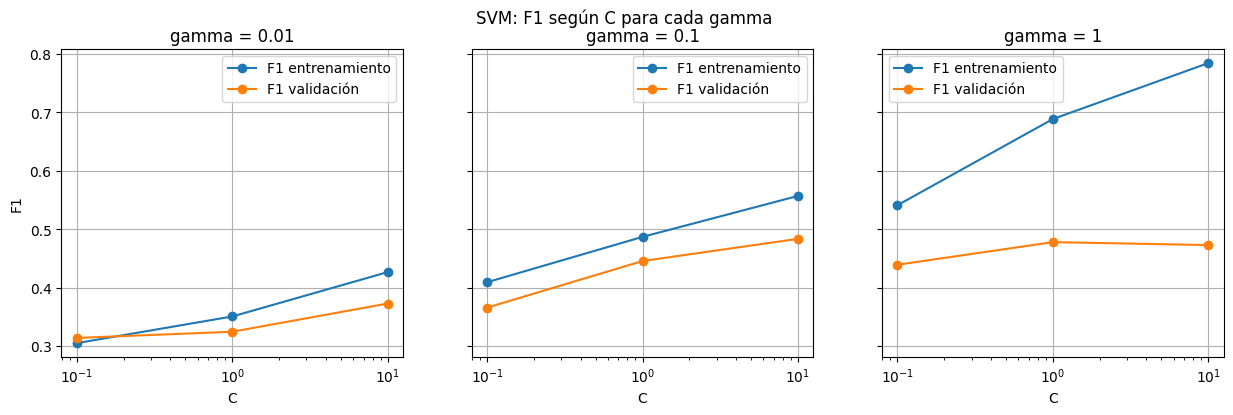

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for eje, gamma in zip(ejes, valores_gamma):
    f1_train = [tabla_svm_train.loc[(C, gamma), 'F1'] for C in valores_C]
    f1_val = [tabla_svm_val.loc[(C, gamma), 'F1'] for C in valores_C]

    eje.plot(valores_C, f1_train, marker='o', label='F1 entrenamiento')
    eje.plot(valores_C, f1_val, marker='o', label='F1 validación')

    eje.set_title(f'gamma = {gamma}')
    eje.set_xscale('log')
    eje.set_xlabel('C')
    eje.grid(True)
    eje.legend()

ejes[0].set_ylabel('F1')
plt.suptitle('SVM: F1 según C para cada gamma')
plt.show()

**Resultados SVM.**
Con valores bajos de `gamma` el F1 es bajo tanto en entrenamiento como en validación, lo que indica subajuste. Al aumentar `gamma` y `C` el F1 de entrenamiento sigue subiendo, pero el de validación se estabiliza cerca de 0,47-0,48, por lo que la diferencia crece y aparece sobreajuste.

Se elige `C = 10` y `gamma = 0,1`, que tiene el mayor F1 de validación (0,483), con poca diferencia entre entrenamiento y validación y un recall de 0,75.

In [ ]:
mejores_hiperparametros = {
    'Gaussian NB': {'var_smoothing': 1e-3},
    'Decision Tree': {'max_depth': 8},
    'Random Forest': {'n_estimators': 10},
    'SVM': {'C': 10, 'gamma': 0.1}
}

resumen_hiperparametros = pd.DataFrame({
    'Modelo': list(mejores_hiperparametros.keys()),
    'Hiperparámetros elegidos': [str(v) for v in mejores_hiperparametros.values()]
}).set_index('Modelo')

display(resumen_hiperparametros)

,Hiperparámetros elegidos
Modelo,
Gaussian NB,{'var_smoothing': 0.001}
Decision Tree,{'max_depth': 8}
Random Forest,{'n_estimators': 10}
SVM,"{'C': 10, 'gamma': 0.1}"


## **Fase 6: Validación cruzada**

hasta ahora los modelos se comparan con un unico conjunto de validación. La validación cruzada repite la evaluación 5 veces con datos distintos para ver si el desempeño de cada modelo es estable.

Se usa `StratifiedKFold` con 5 particiones sobre el conjunto de entrenamiento real sin el balanceo. Cada partición conserva la proporción de fallas, y se usan las mismas para los 4 modelos. En cada vuelta, 4 particiones se usan para entrenar y 1 para evaluar. Las tecnicas de balanceo y y RobustScaler
se ajusta solo con las 4 particiones de entrenamiento de esa vuelta, y la partición de evaluación se deja con su proporción real.

In [ ]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def crear_modelo(nombre):
    if nombre == 'Gaussian NB':
        vs = mejores_hiperparametros['Gaussian NB']['var_smoothing']
        return GaussianNB(var_smoothing=vs)

    if nombre == 'Decision Tree':
        md = mejores_hiperparametros['Decision Tree']['max_depth']
        return DecisionTreeClassifier(max_depth=md, random_state=SEED)

    if nombre == 'Random Forest':
        ne = mejores_hiperparametros['Random Forest']['n_estimators']
        return RandomForestClassifier(n_estimators=ne, random_state=SEED)

    if nombre == 'SVM':
        c = mejores_hiperparametros['SVM']['C']
        g = mejores_hiperparametros['SVM']['gamma']
        return SVC(kernel='rbf', C=c, gamma=g, random_state=SEED)

nombres_modelos = list(mejores_hiperparametros.keys())
print(nombres_modelos)

['Gaussian NB', 'Decision Tree', 'Random Forest', 'SVM']


In [ ]:
filas_cv = []

for nombre in nombres_modelos:
    for fold, (idx_tr, idx_va) in enumerate(skf.split(X_train, y_train_bin), start=1):
       #se hace el balanceo de lass 4 particiones de entrenamieto
        X_tr, y_tr = X_train.iloc[idx_tr], y_train_bin.iloc[idx_tr]
        X_va, y_va = X_train.iloc[idx_va], y_train_bin.iloc[idx_va]


        X_tr_bal, y_tr_bal = SMOTE(random_state=SEED).fit_resample(X_tr, y_tr)

        #Aqui el escalado solo para svm
        if nombre == 'SVM':
            escalador = RobustScaler()
            escalador.fit(X_tr)
            X_tr_bal = escalador.transform(X_tr_bal)
            X_va = escalador.transform(X_va)


        modelo = crear_modelo(nombre)
        modelo.fit(X_tr_bal, y_tr_bal)
        pred = modelo.predict(X_va)


        fila = metricas(y_va, pred)
        fila['Modelo'] = nombre
        fila['Fold'] = fold
        filas_cv.append(fila)

df_cv = pd.DataFrame(filas_cv)
display(df_cv)

,Accuracy,Precision,Recall,Especificidad,F1,Modelo,Fold
0,0.871452,0.149068,0.585366,0.881590,0.237624,Gaussian NB,1
1,0.895659,0.208333,0.731707,0.901469,0.324324,Gaussian NB,2
2,0.880634,0.181250,0.707317,0.886776,0.288557,Gaussian NB,3
3,0.885547,0.191083,0.750000,0.890233,0.304569,Gaussian NB,4
4,0.882206,0.182390,0.725000,0.887640,0.291457,Gaussian NB,5
5,0.956594,0.412698,0.634146,0.968021,0.500000,Decision Tree,1
6,0.943239,0.348315,0.756098,0.949870,0.476923,Decision Tree,2
7,0.940735,0.343750,0.804878,0.945549,0.481752,Decision Tree,3
8,0.942356,0.337079,0.750000,0.949006,0.465116,Decision Tree,4
9,0.956558,0.414286,0.725000,0.964564,0.527273,Decision Tree,5


In [ ]:
columnas = ['Accuracy', 'Precision', 'Recall', 'Especificidad', 'F1']

resumen = df_cv.groupby('Modelo')[columnas].agg(['mean', 'std']).loc[nombres_modelos]

tabla_cv = pd.DataFrame({
    c: resumen[c]['mean'].map('{:.3f}'.format) + ' ± ' + resumen[c]['std'].map('{:.3f}'.format)
    for c in columnas
})

display(tabla_cv)

,Accuracy,Precision,Recall,Especificidad,F1
Modelo,,,,,
Gaussian NB,0.883 ± 0.009,0.182 ± 0.022,0.700 ± 0.066,0.890 ± 0.007,0.289 ± 0.032
Decision Tree,0.948 ± 0.008,0.371 ± 0.039,0.734 ± 0.063,0.955 ± 0.010,0.490 ± 0.024
Random Forest,0.970 ± 0.004,0.553 ± 0.047,0.680 ± 0.032,0.980 ± 0.004,0.609 ± 0.030
SVM,0.943 ± 0.009,0.356 ± 0.048,0.793 ± 0.045,0.949 ± 0.010,0.490 ± 0.047


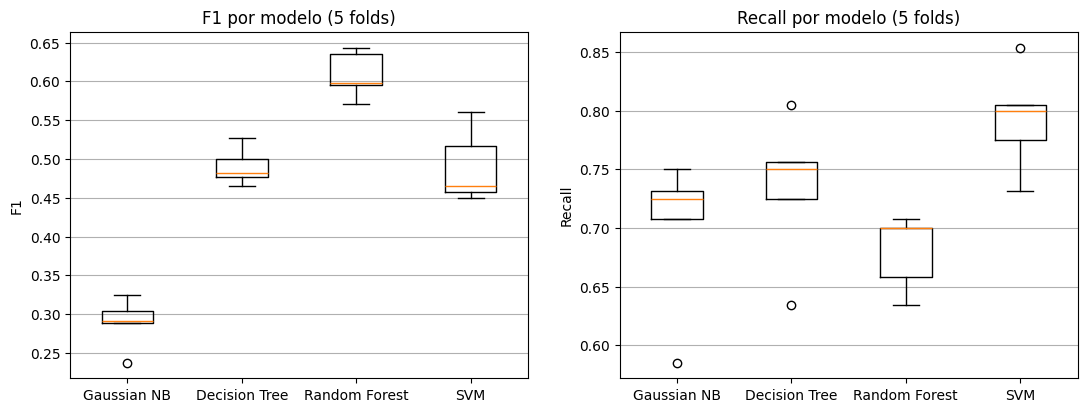

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

for eje, metrica in zip(ejes, ['F1', 'Recall']):
    datos = [df_cv[df_cv['Modelo'] == m][metrica] for m in nombres_modelos]
    eje.boxplot(datos)
    eje.set_xticks(range(1, len(nombres_modelos) + 1))
    eje.set_xticklabels(nombres_modelos)
    eje.set_title(f'{metrica} por modelo (5 folds)')
    eje.set_ylabel(metrica)
    eje.grid(True, axis='y')

plt.show()

###**Boxplots**

Cada caja resume los 5 valores de una métrica (uno por fold) de un modelo. La línea central es la mediana, y la caja contiene el 50 % central de los valores (del primer al tercer cuartil). Los bigotes llegan hasta el valor más alejado y los puntos fuera de ese límite son atípicos.

La posición de la caja indica el desempeño del modelo (más arriba es mejor) y su altura indica la estabilidad, una caja angosta significa que el modelo rinde de forma parecida en todos los folds.

Si las cajas de dos modelos están casi a la misma altura, la diferencia entre ellos es pequeña comparada con la variación entre folds, y no se puede afirmar que uno sea mejor que el otro.

##**Fase 7: Elegir el mejor modelo:**

In [ ]:
filas_comp = []

for nombre in nombres_modelos:
    modelo = crear_modelo(nombre)

    if nombre == 'SVM':
        modelo.fit(X_train_svm, y_train_bal)
        pred = modelo.predict(X_val_svm)
    else:
        modelo.fit(X_train_bal, y_train_bal)
        pred = modelo.predict(X_val)

    fila = metricas(y_val_bin, pred)
    fila['Modelo'] = nombre
    filas_comp.append(fila)

tabla_comparacion = pd.DataFrame(filas_comp).set_index('Modelo')
tabla_comparacion = tabla_comparacion.sort_values(['F1', 'Recall'], ascending=False)

display(tabla_comparacion)

,Accuracy,Precision,Recall,Especificidad,F1
Modelo,,,,,
Random Forest,0.970456,0.551724,0.705882,0.979782,0.619355
Decision Tree,0.947421,0.368794,0.764706,0.953862,0.497608
SVM,0.945418,0.356643,0.750000,0.952307,0.483412
Gaussian NB,0.878317,0.177122,0.705882,0.884396,0.283186


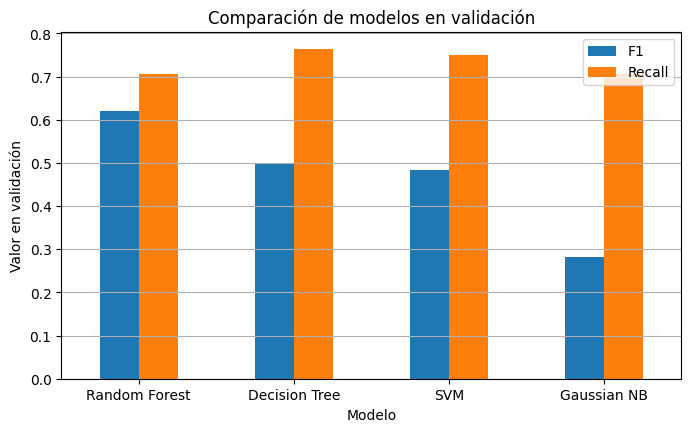

In [ ]:
tabla_comparacion[['F1', 'Recall']].plot(kind='bar', figsize=(8, 4.5))
plt.ylabel('Valor en validación')
plt.title('Comparación de modelos en validación')
plt.xticks(rotation=0)
plt.grid(True, axis='y')
plt.show()

La gráfica muestra, para cada uno de los 4 modelos, el F1 y el recall de la clase de falla en el conjunto de validación. Cada modelo se entrenó con su mejor configuración y con el mismo conjunto de entrenamiento balanceado. Una barra más alta indica mejor desempeño. El F1 resume el equilibrio entre detectar las fallas (recall) y evitar falsas alarmas (precision), y por eso es la métrica con la que se elige el modelo. El recall se muestra aparte para verificar que el modelo ganador no consiga un F1 alto a costa de dejar pasar muchas fallas reales.

In [ ]:
ganador = tabla_comparacion.index[0]

print("Modelo ganador:", ganador)
print("F1:", tabla_comparacion.loc[ganador, 'F1'])
print("Recall:", tabla_comparacion.loc[ganador, 'Recall'])

Modelo ganador: Random Forest
F1: 0.6193548387096774
Recall: 0.7058823529411765


Al comparar los 4 modelos en el conjunto de validación, Random Forest obtuvo el mayor F1 de la clase de falla (0,619), con un recall de 0,706, es decir, detecta cerca del 71 % de las fallas reales. En la validación cruzada también tuvo el mayor F1 (0,609 ± 0,030), unos 0,12 por encima de Decision Tree y SVM (0,490), con una variación entre folds baja, menor que la del SVM (± 0,047). Su recall en validación cruzada (0,680) es algo menor que el del SVM (0,793) y el de Decision Tree (0,734), pero su precision es mucho mayor , por lo que genera menos falsos positivos y no gana el F1 a costa de perder fallas. Por estas razones se elige Random Forest para continuar con los resultados del binario y el paso al multiclase.

##**Fase 8: Matríz de confusción y reporte del binario**

Se toma el Random Forest elegido en la fase anterior, con sus hiperparámetros ya definidos, y se analiza en el conjunto de validación dónde se equivoca: cuántas fallas detecta (TP), cuántas deja pasar (FN) y cuántas falsas alarmas genera (FP).

Para esto se usan el `classification_report` y la matriz de confusión, y se comprueba a mano la precision, el F1 y el recall. Al final se compara la matriz de los cuatro modelos.

              precision    recall  f1-score   support

No falla (0)      0.990     0.980     0.985      1929
   Falla (1)      0.552     0.706     0.619        68

    accuracy                          0.970      1997
   macro avg      0.771     0.843     0.802      1997
weighted avg      0.975     0.970     0.972      1997



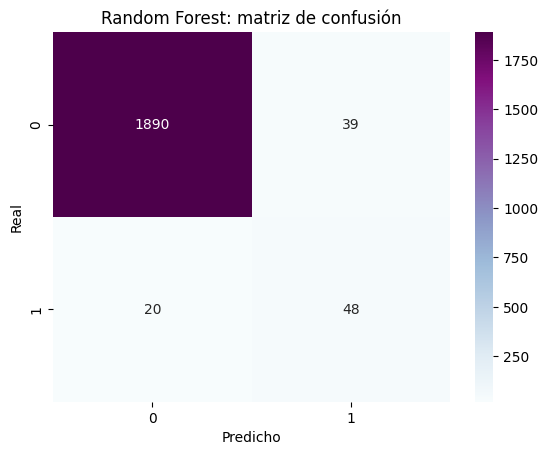

In [ ]:
#@title **Modelo ganador en validación**

if ganador != 'Random Forest':
    print(f"CUIDADO: el ganador ahora es {ganador}, revisar las fases anteriores")

modelo_final = crear_modelo('Random Forest')
modelo_final.fit(X_train_bal, y_train_bal)
pred_val_bin = modelo_final.predict(X_val)

print(classification_report(y_val_bin, pred_val_bin, target_names=['No falla (0)', 'Falla (1)'], digits=3))

matriz_confusion = pd.crosstab(y_val_bin, pred_val_bin, rownames=['Real'], colnames=['Predicho'])
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='BuPu')
plt.title('Random Forest: matriz de confusión')
plt.show()

In [ ]:
#Recall, F1 y Presicion a mano

tn, fp, fn, tp = confusion_matrix(y_val_bin, pred_val_bin, labels=[0, 1]).ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

precision_mano = tp / (tp + fp)
recall_mano = tp / (tp + fn)
f1_mano = 2 * tp / (2 * tp + fp + fn)

comparacion = pd.DataFrame({
    'A mano': [precision_mano, recall_mano, f1_mano],
    'sklearn': [precision_score(y_val_bin, pred_val_bin),
                recall_score(y_val_bin, pred_val_bin),
                f1_score(y_val_bin, pred_val_bin)]
}, index=['Precision', 'Recall', 'F1']).round(4)

display(comparacion)

print(f"\nFallas reales en validación: {tp + fn}")
print(f"Fallas detectadas (TP): {tp}")
print(f"Fallas que se dejan pasar (FN): {fn}")
print(f"Falsas alarmas (FP): {fp}")

TN = 1890 | FP = 39 | FN = 20 | TP = 48


,A mano,sklearn
Precision,0.5517,0.5517
Recall,0.7059,0.7059
F1,0.6194,0.6194



Fallas reales en validación: 68
Fallas detectadas (TP): 48
Fallas que se dejan pasar (FN): 20
Falsas alarmas (FP): 39


###Observación:
Podemos ver que la matriz de confusión de Random Forest detecta la mayoria de los fallos (de las 68 fallas, dejo pasar 20) con un Recall de 0.706, lo que nos dice que 3 de cada 10 fallos no los detecta.

Ademas, genera 39 falsas alarmas de las 87 que registra. Por eso la precision es 0,552, aproximadamente 1 de cada 2 alarmas es falsa.

Tambien, con un F1 = 0,619 el modelo sirve como apoyo para priorizar revisiones, pero no para confiar en que no se escape ninguna falla.

El modelo reconoce bien las máquinas sanas, pero aproximadamente 3 de cada 10 fallas no se detectan y 1 de cada 2 alarmas es falsa. Dado que en mantenimiento una falla no detectada cuesta más que una revisión innecesaria, el recall presenta una debilidad en el modelo.

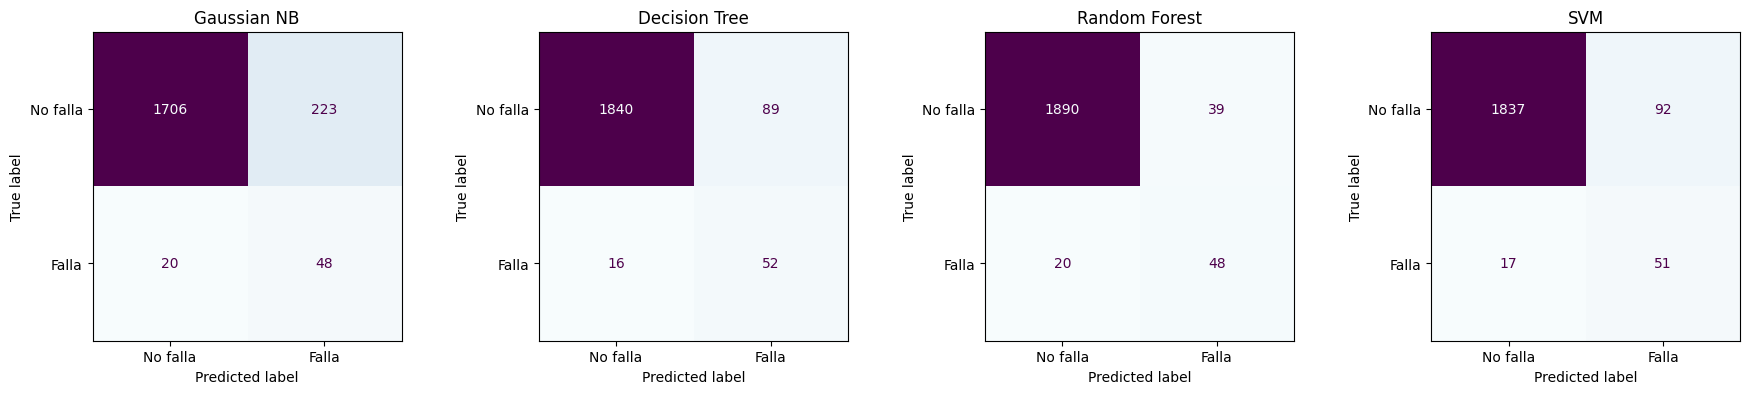

In [ ]:
#Comparando con los otros modelos

fig, ejes = plt.subplots(1, 4, figsize=(18, 4))

for eje, nombre in zip(ejes, nombres_modelos):
    modelo = crear_modelo(nombre)
    if nombre == 'SVM':
        modelo.fit(X_train_svm, y_train_bal)
        pred = modelo.predict(X_val_svm)
    else:
        modelo.fit(X_train_bal, y_train_bal)
        pred = modelo.predict(X_val)

    #Uso de la funcion de sklearn
    ConfusionMatrixDisplay.from_predictions(y_val_bin, pred, labels=[0, 1],
        display_labels=['No falla', 'Falla'], cmap='BuPu', ax=eje, colorbar=False)
    eje.set_title(nombre)

plt.tight_layout()
plt.show()

Al comparar las matrices de confusión en validación, los cuatro modelos detectan un número similar de fallas (entre 48 y 52 de 68), por lo que sus recalls pueden ser parecidos, la diferencia principal está en las falsas alarmas. El Random Forest genera 39, frente a 89 del Decision Tree, 92 del SVM y 223 del Gaussian Naive Bayes. Por eso tiene la mayor precision (0,552) y el mayor F1 (0,619), y esto respalda la elección del Random Forest, sin que gane el F1 a costa de perder fallas.

#**Fase 9: Pasar a multiclase con el modelo elegido**

Se toma el Random Forest con los mismos hiperparámetros del binario (`n_estimators = 10`) y se entrena para predecir el tipo de falla (5 clases), sin volver a elegir ni ajustar nada. Se usa la misma partición y el mismo balanceo con SMOTE, aplicado solo sobre entrenamiento.

La métrica principal es el F1 macro, y se reportan el F1 ponderado y la accuracy como referencia. Como algunas clases tienen muy pocos casos, los resultados por clase serán inestables.

In [ ]:
# Tamaño de cada clase

etiquetas = list(range(len(nombres_clases)))

conteo = pd.DataFrame({'Train': y_train_multi.value_counts(),
                       'Validación': y_val_multi.value_counts(),
                       'Test': y_test_multi.value_counts()}).sort_index()
conteo.index = nombres_clases
display(conteo)

,Train,Validación,Test
Heat Dissipation Failure,66,18,28
No Failure,5790,1933,1929
Overstrain Failure,48,13,17
Power Failure,57,20,18
Tool Wear Failure,27,13,5


Train balanceado multiclase:
 0    5790
1    5790
2    5790
3    5790
4    5790
Name: count, dtype: int64
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.857     1.000     0.923        18
              No Failure      0.991     0.988     0.989      1933
      Overstrain Failure      0.625     0.769     0.690        13
           Power Failure      0.696     0.800     0.744        20
       Tool Wear Failure      0.222     0.154     0.182        13

                accuracy                          0.979      1997
               macro avg      0.678     0.742     0.706      1997
            weighted avg      0.979     0.979     0.979      1997



,Valor
F1 macro (principal),0.7056
F1 ponderado,0.9791
Accuracy (referencia),0.9795


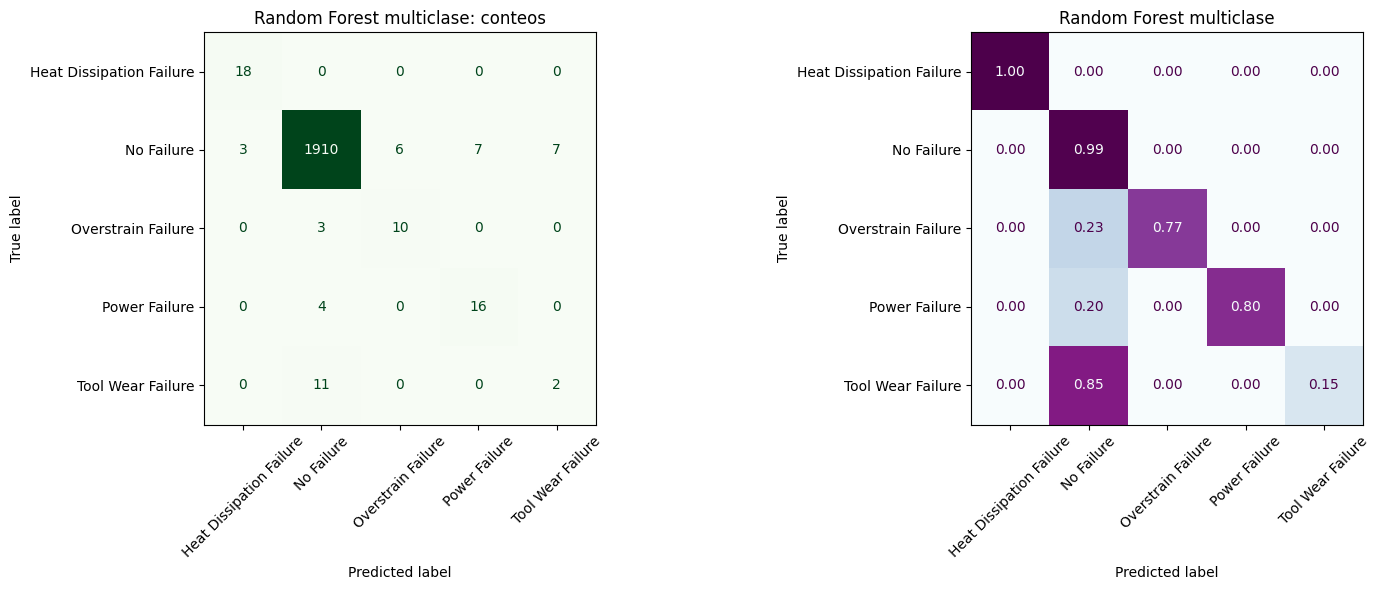

In [ ]:
#@title **Random Forest multiclase**

X_train_bal_m, y_train_bal_m = SMOTE(random_state=SEED).fit_resample(X_train, y_train_multi)
print("Train balanceado multiclase:\n", y_train_bal_m.value_counts().sort_index())

modelo_multi = crear_modelo('Random Forest')
modelo_multi.fit(X_train_bal_m, y_train_bal_m)
pred_val_multi = modelo_multi.predict(X_val)

print(classification_report(y_val_multi, pred_val_multi, labels=etiquetas, target_names=nombres_clases, digits=3, zero_division=0))

multiclase = pd.DataFrame({'Valor': [
    f1_score(y_val_multi, pred_val_multi, average='macro', zero_division=0),
    f1_score(y_val_multi, pred_val_multi, average='weighted', zero_division=0),
    accuracy_score(y_val_multi, pred_val_multi)]},
    index=['F1 macro (principal)', 'F1 ponderado', 'Accuracy (referencia)']).round(4)
display(multiclase)
print("\n      ")

#Matriz de confusión
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(y_val_multi, pred_val_multi, labels=etiquetas,
    display_labels=nombres_clases, cmap='Greens', xticks_rotation=45, ax=ejes[0], colorbar=False)
ejes[0].set_title('Random Forest multiclase: conteos')

ConfusionMatrixDisplay.from_predictions(y_val_multi, pred_val_multi, labels=etiquetas,
    display_labels=nombres_clases, normalize='true', values_format='.2f',
    cmap='BuPu', xticks_rotation=45, ax=ejes[1], colorbar=False)
ejes[1].set_title('Random Forest multiclase')

plt.tight_layout()
plt.show()

Algunos tipos de falla tienen muy pocos casos en entrenamiento (Tool Wear 27, Overstrain 48, Power 57, frente a 5790 de `No Failure`), por lo que se aplicó SMOTE solo sobre entrenamiento. En validación, el Random Forest obtiene un F1 macro de 0,706, mientras que el F1 ponderado (0,979) y la accuracy (0,980) son más altos porque `No Failure` domina.


,Precision,Recall,F1,Casos en validación
Heat Dissipation Failure,0.857,1.000,0.923,18
No Failure,0.991,0.988,0.989,1933
Overstrain Failure,0.625,0.769,0.690,13
Power Failure,0.696,0.800,0.744,20
Tool Wear Failure,0.222,0.154,0.182,13


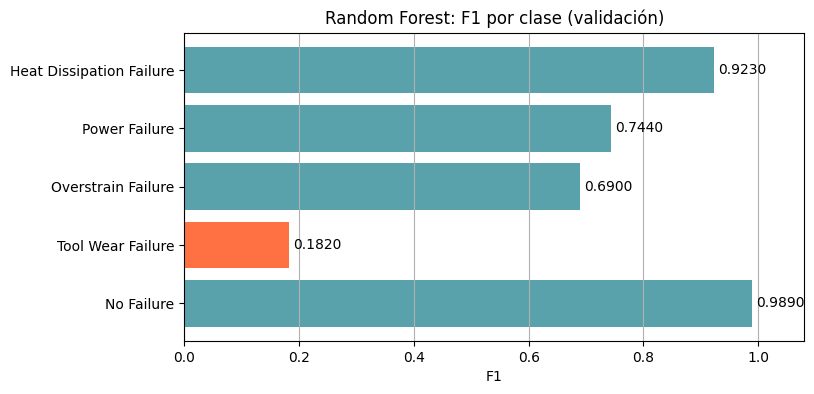


      
Heat Dissipation Failure: sin errores
No Failure: 23 errores de 1933 casos; se confunde más con 'Power Failure' (7)
Overstrain Failure: 3 errores de 13 casos; se confunde más con 'No Failure' (3)
Power Failure: 4 errores de 20 casos; se confunde más con 'No Failure' (4)
Tool Wear Failure: 11 errores de 13 casos; se confunde más con 'No Failure' (11)


In [ ]:
# Grafico de barras de F1 por cada clase
prec, rec, f1_clases, soporte = precision_recall_fscore_support(
    y_val_multi, pred_val_multi, labels=etiquetas, zero_division=0)

tabla_clases = pd.DataFrame({'Precision': prec, 'Recall': rec, 'F1': f1_clases,
                             'Casos en validación': soporte}, index=nombres_clases).round(3)
display(tabla_clases)

orden_fallas = [n for n in tabla_clases.sort_values('F1', ascending=False).index if n != 'No Failure']
orden = orden_fallas + ['No Failure']
f1_orden = tabla_clases.loc[orden, 'F1']

colores = ['#FF7043' if v == f1_orden.min() else '#5AA2AB' for v in f1_orden]

plt.figure(figsize=(8, 4))
barras = plt.barh(orden, f1_orden.values, color=colores)
plt.bar_label(barras, fmt='%.4f', padding=3)
plt.gca().invert_yaxis()
plt.xlabel('F1')
plt.xlim(0, 1.08)
plt.title('Random Forest: F1 por clase (validación)')
plt.grid(True, axis='x')
plt.show()

print("\n      ")

cm = confusion_matrix(y_val_multi, pred_val_multi, labels=etiquetas)
matriz_multi = pd.DataFrame(cm, index=nombres_clases, columns=nombres_clases)

for nombre in nombres_clases:
    fila = matriz_multi.loc[nombre]
    errores = fila.drop(nombre)

    if errores.sum() > 0:
        print(f"{nombre}: {errores.sum()} errores de {fila.sum()} casos; "
              f"se confunde más con '{errores.idxmax()}' ({errores.max()})")
    else:
        print(f"{nombre}: sin errores")

Heat Dissipation es la clase mejor detectada (F1 0,923), seguida de Power (0,744) y Overstrain (0,690). Tool Wear es la peor (F1 0,182): 11 de sus 13 casos en validación se clasifican como `No Failure`, lo que coincide con ser la clase con menos ejemplos reales (27 en entrenamiento).

Esto nos dice que cuando el modelo detecta una falla casi siempre acierta el tipo, y el problema principal es dejar pasar fallas, sobre todo de Tool Wear.

###**Observación:**

Al pasar al multiclase con el mismo Random Forest y los mismos hiperparámetros obtenemos un F1 macro de 0,706 en validación. El modelo identifica bien el tipo en Heat Dissipation, Power y Overstrain, pero casi no detecta Tool Wear, casi todos los errores son fallas que se clasifican como `No Failure`, por lo que el multiclase hereda del binario: cerca de 3 de cada 10 fallas se dejan pasar.

Una limitación es que las clases pequeñas dan resultados inestables, el F1 macro incluye a `No Failure` (F1 0,989), se eliminó `Random Failures` y la partición está estratificada por `y_bin` y no por tipo de falla.


###**Justificación de la eliminación de Random Failures**
Para comprobar que quitar esta clase fue una buena decisión, se entrena el mismo Random Forest con las 6 clases originales y con 5 clases (sin Random Failures), usando las mismas filas, y se comparan el F1 por clase y el F1 macro.

In [ ]:

filas_rf = df_completo[df_completo["Failure Type"] == "Random Failures"]
X_rf = filas_rf.drop(columns=["UDI", "Product ID", "Type", "Target", "Failure Type"])
X_rf = X_rf[X_train.columns]


X_rf_dev, X_rf_test = train_test_split(X_rf, test_size=4, random_state=SEED)
X_rf_train, X_rf_val = train_test_split(X_rf_dev, test_size=4, random_state=SEED)

cod_rf = len(nombres_clases)
etiquetas_6 = etiquetas + [cod_rf]
nombres_6 = nombres_clases + ["Random Failures"]


X_train_6 = pd.concat([X_train, X_rf_train], ignore_index=True)
y_train_6 = pd.concat([y_train_multi, pd.Series(cod_rf, index=X_rf_train.index)], ignore_index=True)

X_val_6 = pd.concat([X_val, X_rf_val], ignore_index=True)
y_val_6 = pd.concat([y_val_multi, pd.Series(cod_rf, index=X_rf_val.index)], ignore_index=True)

print("Random Failures: train:", len(X_rf_train), "| validación:", len(X_rf_val))

X_train_bal_6, y_train_bal_6 = SMOTE(random_state=SEED).fit_resample(X_train_6, y_train_6)

modelo_multi_6 = crear_modelo('Random Forest')
modelo_multi_6.fit(X_train_bal_6, y_train_bal_6)
pred_val_6 = modelo_multi_6.predict(X_val_6)

print(classification_report(y_val_6, pred_val_6, labels=etiquetas_6,
                            target_names=nombres_6, digits=3, zero_division=0))

Random Failures: train: 10 | validación: 4
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.750     1.000     0.857        18
              No Failure      0.988     0.984     0.986      1933
      Overstrain Failure      0.692     0.692     0.692        13
           Power Failure      0.636     0.700     0.667        20
       Tool Wear Failure      0.200     0.154     0.174        13
         Random Failures      0.000     0.000     0.000         4

                accuracy                          0.973      2001
               macro avg      0.544     0.588     0.563      2001
            weighted avg      0.973     0.973     0.973      2001



In [ ]:
#Comparacion
f1_5 = precision_recall_fscore_support(y_val_multi, pred_val_multi, labels=etiquetas, zero_division=0)[2]
f1_6 = precision_recall_fscore_support(y_val_6, pred_val_6, labels=etiquetas_6, zero_division=0)[2]

tabla_rf = pd.DataFrame({
    'Sin Random Failures (5 clases)': pd.Series(f1_5, index=nombres_clases),
    'Con Random Failures (6 clases)': pd.Series(f1_6, index=nombres_6)
})


tabla_rf.loc['F1 macro (5 clases comunes)'] = [
    f1_score(y_val_multi, pred_val_multi, average='macro', zero_division=0),
    f1_score(y_val_6, pred_val_6, labels=etiquetas, average='macro', zero_division=0)]

# F1 macro con todas las clases de cada versión
tabla_rf.loc['F1 macro (todas las clases)'] = [
    f1_score(y_val_multi, pred_val_multi, average='macro', zero_division=0),
    f1_score(y_val_6, pred_val_6, labels=etiquetas_6, average='macro', zero_division=0)]

display(tabla_rf)


,Sin Random Failures (5 clases),Con Random Failures (6 clases)
Heat Dissipation Failure,0.923077,0.857143
No Failure,0.989381,0.986266
Overstrain Failure,0.689655,0.692308
Power Failure,0.744186,0.666667
Random Failures,NaN,0.000000
Tool Wear Failure,0.181818,0.173913
F1 macro (5 clases comunes),0.705623,0.675259
F1 macro (todas las clases),0.705623,0.562716


#**fase 10:  Evaluación final en el test**



Con el modelo y los hiperparámetros ya fijados (Random Forest, `n_estimators = 10`), se reentrena con entrenamiento y validación juntos aplicando SMOTE solo sobre ellos, y se evalúa una única vez en el conjunto de test, tanto para el binario como para el multiclase. Después de ver estos resultados no se ajusta nada más.

              precision    recall  f1-score   support

No falla (0)      0.994     0.982     0.988      1929
   Falla (1)      0.615     0.824     0.704        68

    accuracy                          0.976      1997
   macro avg      0.805     0.903     0.846      1997
weighted avg      0.981     0.976     0.978      1997



,Validación,Test
Accuracy,0.970456,0.976465
Precision,0.551724,0.615385
Recall,0.705882,0.823529
Especificidad,0.979782,0.981856
F1,0.619355,0.704403


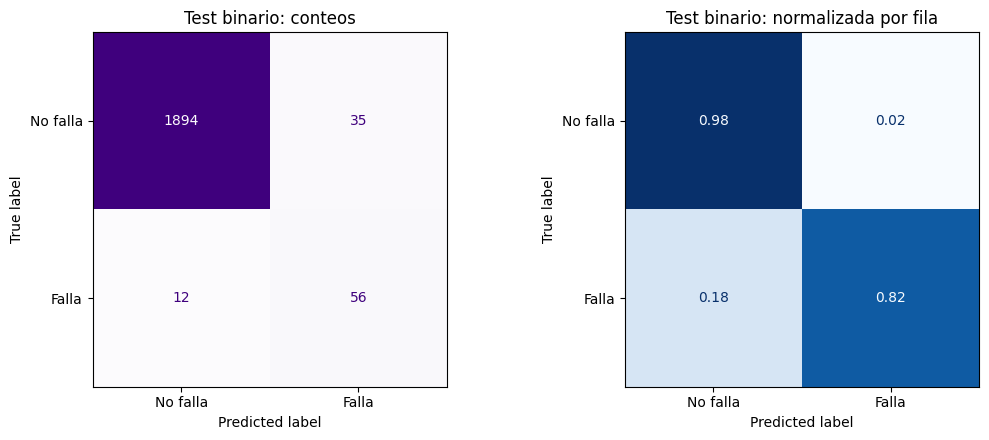

In [ ]:
#@title **Test binario**

X_dev_bal, y_dev_bal = SMOTE(random_state=SEED).fit_resample(X_dev, y_dev_bin)
rf_test = crear_modelo('Random Forest')
rf_test.fit(X_dev_bal, y_dev_bal)
pred_test_bin = rf_test.predict(X_test)

print(classification_report(y_test_bin, pred_test_bin, target_names=['No falla (0)', 'Falla (1)'], digits=3))

comparacion_bin = pd.DataFrame({'Validación': metricas(y_val_bin, pred_val_bin),
                                'Test': metricas(y_test_bin, pred_test_bin)})
display(comparacion_bin)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test_bin, pred_test_bin, labels=[0, 1],
    display_labels=['No falla', 'Falla'], cmap='Purples', ax=ejes[0], colorbar=False)
ejes[0].set_title('Test binario: conteos')

ConfusionMatrixDisplay.from_predictions(y_test_bin, pred_test_bin, labels=[0, 1],
    display_labels=['No falla', 'Falla'], normalize='true', values_format='.2f',
    cmap='Blues', ax=ejes[1], colorbar=False)
ejes[1].set_title('Test binario: normalizada por fila')

plt.tight_layout()
plt.show()


En el binario, el Random Forest entrenado con train y validación obtiene en test un F1 de 0,704 y un recall de 0,824:

detecta 56 de las 68 fallas y deja pasar 12, con 35 falsas alarmas sobre 1929 máquinas sanas (especificidad 0,982). La precision es 0,615, es decir, algo más de 6 de cada 10 alarmas son fallas reales. Estos valores son mejores que los de validación (F1 0,619 y recall 0,706). Con solo 68 fallas, pocos casos cambian bastante las métricas, y además el modelo se entrenó con más datos. Lo importante es que el desempeño se mantiene en el mismo nivel con datos que no se usaron para elegirlo.


                          precision    recall  f1-score   support

Heat Dissipation Failure      0.900     0.964     0.931        28
              No Failure      0.993     0.989     0.991      1929
      Overstrain Failure      0.750     0.706     0.727        17
           Power Failure      0.789     0.833     0.811        18
       Tool Wear Failure      0.000     0.000     0.000         5

                accuracy                          0.982      1997
               macro avg      0.687     0.699     0.692      1997
            weighted avg      0.986     0.982     0.984      1997



,Validación,Test
F1 macro (principal),0.7056,0.6921
F1 ponderado,0.9791,0.9840
Accuracy (referencia),0.9795,0.9825


,Precision,Recall,F1,Casos en test
Heat Dissipation Failure,0.900,0.964,0.931,28
No Failure,0.993,0.989,0.991,1929
Overstrain Failure,0.750,0.706,0.727,17
Power Failure,0.789,0.833,0.811,18
Tool Wear Failure,0.000,0.000,0.000,5


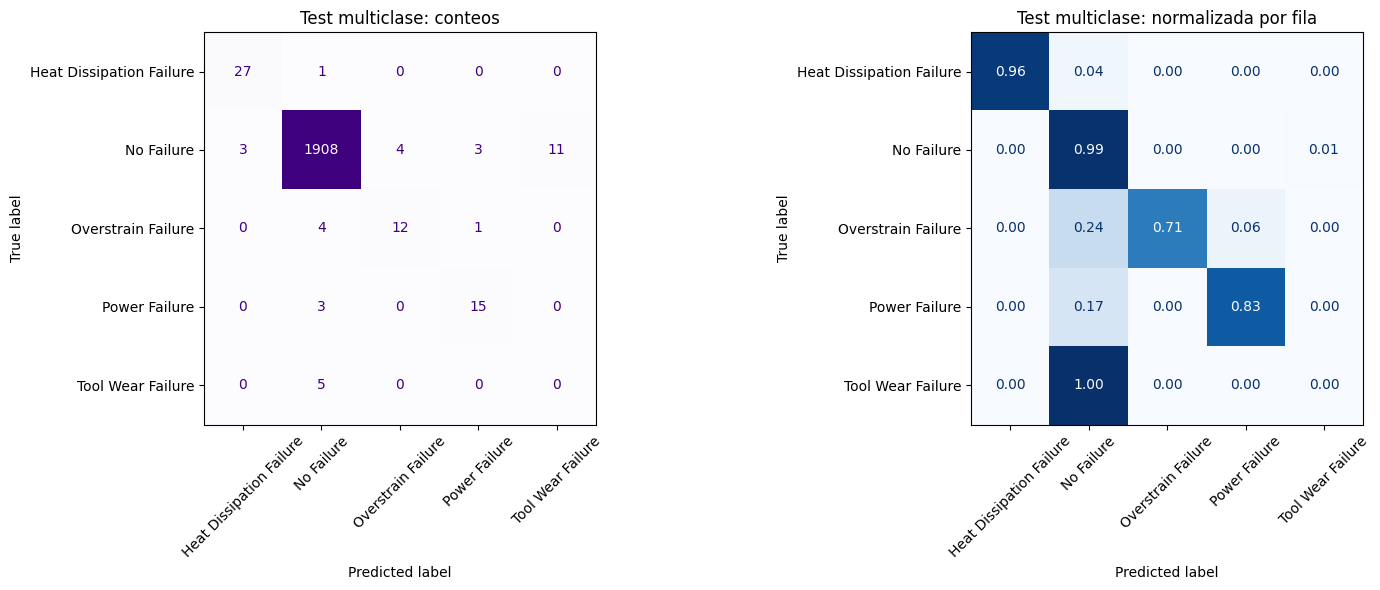

In [ ]:
#@title **Test multiclase**

y_dev_multi = y_multi.loc[X_dev.index]

X_dev_bal_m, y_dev_bal_m = SMOTE(random_state=SEED).fit_resample(X_dev, y_dev_multi)
rf_test_multi = crear_modelo('Random Forest')
rf_test_multi.fit(X_dev_bal_m, y_dev_bal_m)
pred_test_multi = rf_test_multi.predict(X_test)

print(classification_report(y_test_multi, pred_test_multi, labels=etiquetas, target_names=nombres_clases, digits=3, zero_division=0))

reporte_test = pd.DataFrame({
    'Validación': [f1_score(y_val_multi, pred_val_multi, average='macro', zero_division=0),
                   f1_score(y_val_multi, pred_val_multi, average='weighted', zero_division=0),
                   accuracy_score(y_val_multi, pred_val_multi)],
    'Test': [f1_score(y_test_multi, pred_test_multi, average='macro', zero_division=0),
             f1_score(y_test_multi, pred_test_multi, average='weighted', zero_division=0),
             accuracy_score(y_test_multi, pred_test_multi)]},
    index=['F1 macro (principal)', 'F1 ponderado', 'Accuracy (referencia)']).round(4)
display(reporte_test)
print('\n    ')

prec, rec, f1_c, sop = precision_recall_fscore_support(
    y_test_multi, pred_test_multi, labels=etiquetas, zero_division=0)
tabla_test = pd.DataFrame({'Precision': prec, 'Recall': rec, 'F1': f1_c, 'Casos en test': sop}, index=nombres_clases).round(3)
display(tabla_test)
print('\n    ')

#Matriz que describe el tipo de falla que predice el modelo

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(y_test_multi, pred_test_multi, labels=etiquetas,
    display_labels=nombres_clases, cmap='Purples', xticks_rotation=45, ax=ejes[0], colorbar=False)
ejes[0].set_title('Test multiclase: conteos')

ConfusionMatrixDisplay.from_predictions(y_test_multi, pred_test_multi, labels=etiquetas,
    display_labels=nombres_clases, normalize='true', values_format='.2f',
    cmap='Blues', xticks_rotation=45, ax=ejes[1], colorbar=False)
ejes[1].set_title('Test multiclase: normalizada por fila')

plt.tight_layout()
plt.show()

En el multiclase, el F1 macro es 0,692, muy parecido al de validación (0,706). La accuracy (0,982) y el F1 ponderado (0,984) son más altos porque `No Failure` domina el conjunto, por lo que solo se usan como referencia.

Heat Dissipation (F1 0,931), Power (0,811) y Overstrain (0,727) se mantienen bien detectados. Tool Wear Failure no se detecta (F1 0,000): sus 5 casos en test se clasificaron como `No Failure`, aunque con tan pocos casos esta cifra es poco confiable. Los errores siguen el patrón donde casi todos son fallas que se clasifican como `No Failure` y solo hay un caso en que se confunde un tipo de falla con otro (Overstrain predicha como Power).

###**Observacion:**

En general el modelo es útil para priorizar revisiones y reconoce bien el tipo de falla cuando la detecta, pero deja pasar una parte de las fallas, sobre todo las de Tool Wear.


#**Fase 12: Conclusiones y limitaciones**

,0
Rotational speed [rpm],0.301
Torque [Nm],0.246
Tool wear [min],0.198
Temp_diff,0.070
Type_M,0.053
Type_L,0.042
Air temperature [K],0.034
Type_H,0.028
Process temperature [K],0.027


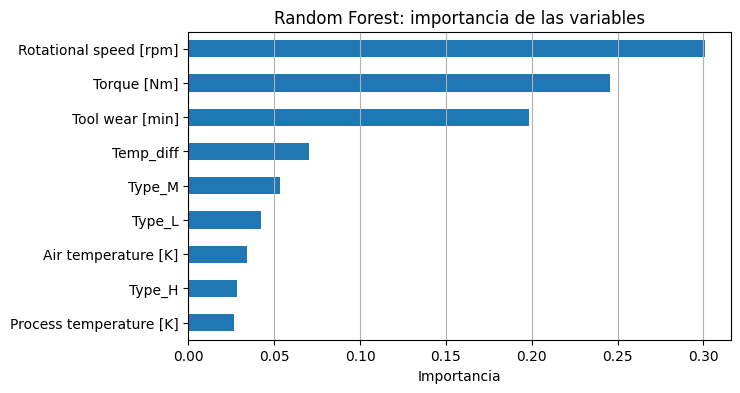

In [ ]:
#Iportancia de las variables
importancias = pd.Series(rf_test.feature_importances_, index=X_dev.columns).sort_values(ascending=False)
display(importancias.round(3))

plt.figure(figsize=(7, 4))
importancias.sort_values().plot(kind='barh')
plt.xlabel('Importancia')
plt.title('Random Forest: importancia de las variables')
plt.grid(True, axis='x')
plt.show()

El gráfico muestra cuánto aporta cada variable a las decisiones del Random Forest, y la suma de todas las importancias es 1. Las tres variables con mayor importancia son Rotational speed, Torque y Tool wear, que juntas suman cerca de 0,75. Les sigue Temp_diff, y las demás variables, entre ellas las temperaturas originales y las columnas de Type, aportan menos.

###**Modelo Elegido:** Se compararon Gaussian Naive Bayes, Decision Tree, Random Forest y SVM, cada uno con los hiperparámetros elegidos en la exploración, usando el F1 de la clase de falla como métrica principal y el recall como apoyo. El Random Forest (`n_estimators = 10`) fue el mejor en validación y en validación cruzada. Su ventaja principal es que genera muchas menos falsas alarmas que los demás modelos, sin detectar menos fallas. Los hiperparámetros y el modelo se eligieron solo con validación, y el test se usó una única vez al final.


###**Detección de la falla (binario):** En test el modelo detecta 56 de las 68 fallas reales y deja pasar 12, con 35 falsas alarmas entre 1929 máquinas sanas. Esto da un recall de 0,824 y un F1 de 0,704, mejores que en validación, una diferencia esperable con tan pocas fallas y con un modelo reentrenado con más datos. Lo importante es que el desempeño se mantiene con datos que no se usaron para elegir el modelo. Aproximadamente 6 de cada 10 alarmas son fallas reales, por lo que el modelo sirve para priorizar revisiones.

###**Tipo de falla(Multiclase):** El F1 macro en test es 0,692, muy cercano al de validación (0,706). El modelo identifica bien Heat Dissipation, Power y Overstrain, y no detecta Tool Wear, cuyos 5 casos de test se clasificaron como No Failure. Casi todos los errores son fallas que se clasifican como No Failure, y solo hay un caso en que se confunde un tipo de falla con otro, así que el multiclase hereda la principal debilidad del binario(Deja pasar fallas reales).

###**Fallas que no se detectan**: El Random Forest tiene un buen desempeño general, pero no reconoce todas las fallas. En test deja pasar 12 de las 68 fallas reales, y en el multiclase estas fallas se clasifican como No Failure, sobre todo las de Tool Wear, que no se detectan en ningún caso. Esto se vio tanto en validación como en test, por lo que no es un resultado aislado. En mantenimiento predictivo una falla no detectada cuesta más que una revisión innecesaria, así que esta es la principal debilidad del modelo y debe tenerse en cuenta antes de usarlo en la práctica.

###**Limitaciones**:Algunos tipos de falla tienen muy pocos casos, sobre todo Tool Wear, así que sus resultados son inestables y poco confiables. La validación y el test tienen solo 68 fallas cada uno, por lo que unos pocos casos cambian bastante las métricas y los resultados dependen de la partición elegida.